In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
%matplotlib inline

In [2]:
df = pd.read_csv("automobiles_clean_df.csv", header=0)

In [3]:
df.head()

,symboling,normalized-losses,make,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,city-mpg,highway-mpg,price,city-L/100km,highway-L/100km,horsepower-binned,fuel-type-diesel,fuel-type-gas,aspiration-std,aspiration-turbo
0,3,122,alfa-romero,two,convertible,rwd,front,88.6,0.811148,0.890278,...,21,27,16500.0,11.190476,8.703704,Low,False,True,True,False
1,2,164,audi,four,sedan,fwd,front,99.8,0.848630,0.919444,...,24,30,13950.0,9.791667,7.833333,Low,False,True,True,False
2,2,164,audi,four,sedan,4wd,front,99.4,0.848630,0.922222,...,18,22,17450.0,13.055556,10.681818,Low,False,True,True,False
3,2,122,audi,two,sedan,fwd,front,99.8,0.851994,0.920833,...,19,25,15250.0,12.368421,9.400000,Low,False,True,True,False
4,1,158,audi,four,sedan,fwd,front,105.8,0.925997,0.991667,...,19,25,17710.0,12.368421,9.400000,Low,False,True,True,False


In [4]:
df.head()

,symboling,normalized-losses,make,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,...,city-mpg,highway-mpg,price,city-L/100km,highway-L/100km,horsepower-binned,fuel-type-diesel,fuel-type-gas,aspiration-std,aspiration-turbo
0,3,122,alfa-romero,two,convertible,rwd,front,88.6,0.811148,0.890278,...,21,27,16500.0,11.190476,8.703704,Low,False,True,True,False
1,2,164,audi,four,sedan,fwd,front,99.8,0.848630,0.919444,...,24,30,13950.0,9.791667,7.833333,Low,False,True,True,False
2,2,164,audi,four,sedan,4wd,front,99.4,0.848630,0.922222,...,18,22,17450.0,13.055556,10.681818,Low,False,True,True,False
3,2,122,audi,two,sedan,fwd,front,99.8,0.851994,0.920833,...,19,25,15250.0,12.368421,9.400000,Low,False,True,True,False
4,1,158,audi,four,sedan,fwd,front,105.8,0.925997,0.991667,...,19,25,17710.0,12.368421,9.400000,Low,False,True,True,False


In [5]:
df.to_csv('automobiles_clean_df.csv', index=False)

In [6]:
#modules for linear regression
from sklearn.linear_model import LinearRegression
lm = LinearRegression()
lm

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [7]:
X = df [["highway-mpg"]]
Y = df["price"]

lm.fit(X, Y)


yhat = lm.predict(X)
yhat[0:5]

array([16258.2689376 , 13788.89891638, 20373.88563964, 17904.51561842,
       17904.51561842])

In [8]:
#intercept and coef
print(f"The y intercept is { lm.intercept_} and the coefficient is {lm.coef_}")


The y intercept is 38482.59912860538 and the coefficient is [-823.12334041]


In [9]:
lm1 = LinearRegression()
X=df[["engine-size"]]
Y=df["price"]

lm1.fit(X,Y)
yhat = lm1.predict(X)
yhat[0:5]

array([13734.37846255, 10228.88677792, 14735.94751531, 14735.94751531,
       14735.94751531])

In [10]:
print(f"The y intercept is { lm1.intercept_} and the coefficient is {lm1.coef_}")

The y intercept is -7966.284347105318 and the coefficient is [166.92817546]


In [11]:
#multiple linear regression
Z = df[["horsepower","curb-weight","engine-size","highway-mpg"]]
Y = df["price"]

In [12]:
lm.fit(Z,Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [13]:
print(f"The y intercept is { lm.intercept_} and the coefficient is {lm.coef_}")

The y intercept is -15939.06836276877 and the coefficient is [54.86114775  4.71004557 80.95463228 38.43821177]


In [14]:
lm2 = LinearRegression()
features = df [["normalized-losses","highway-mpg"]]

lm2.fit(features, df["price"])

print(f"The y intercept is { lm2.intercept_} and the coefficient is {lm2.coef_}")

The y intercept is 38268.63270058251 and the coefficient is [   1.4423987  -821.88691138]


(0.0, 48181.17452117595)

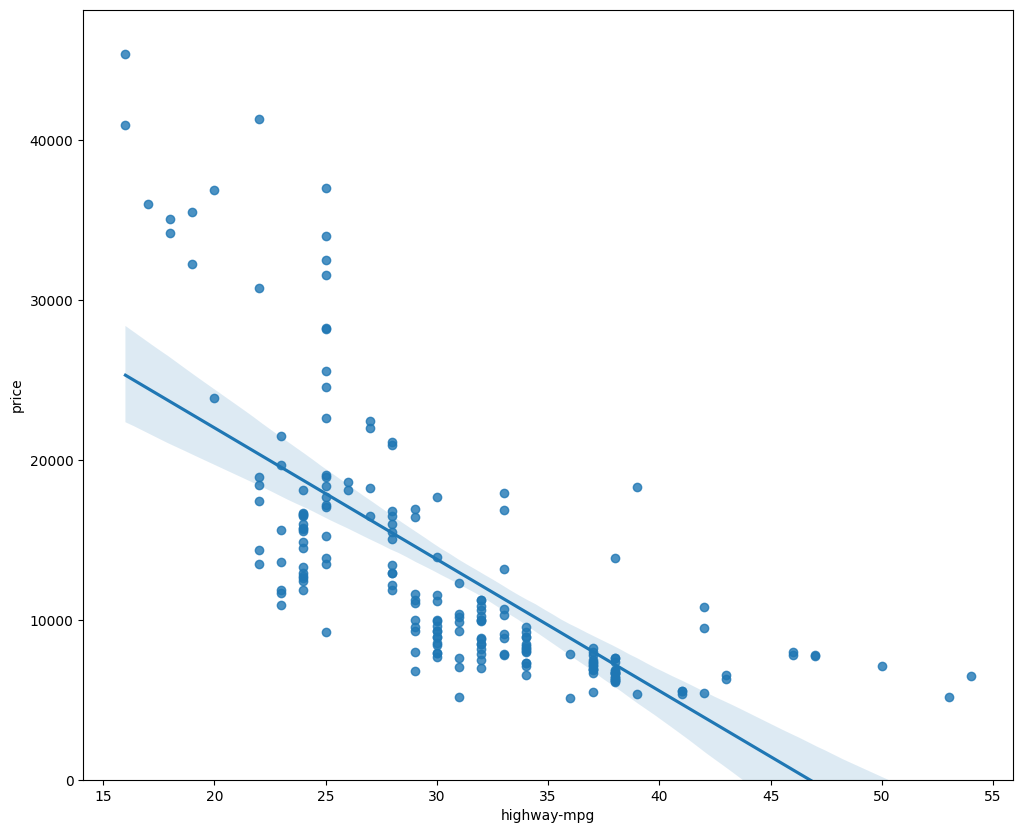

In [15]:
width = 12
height = 10
plt.figure(figsize=(width, height))
sns.regplot(x="highway-mpg", y="price", data = df)
plt.ylim(0,)

(0.0, 47414.1)

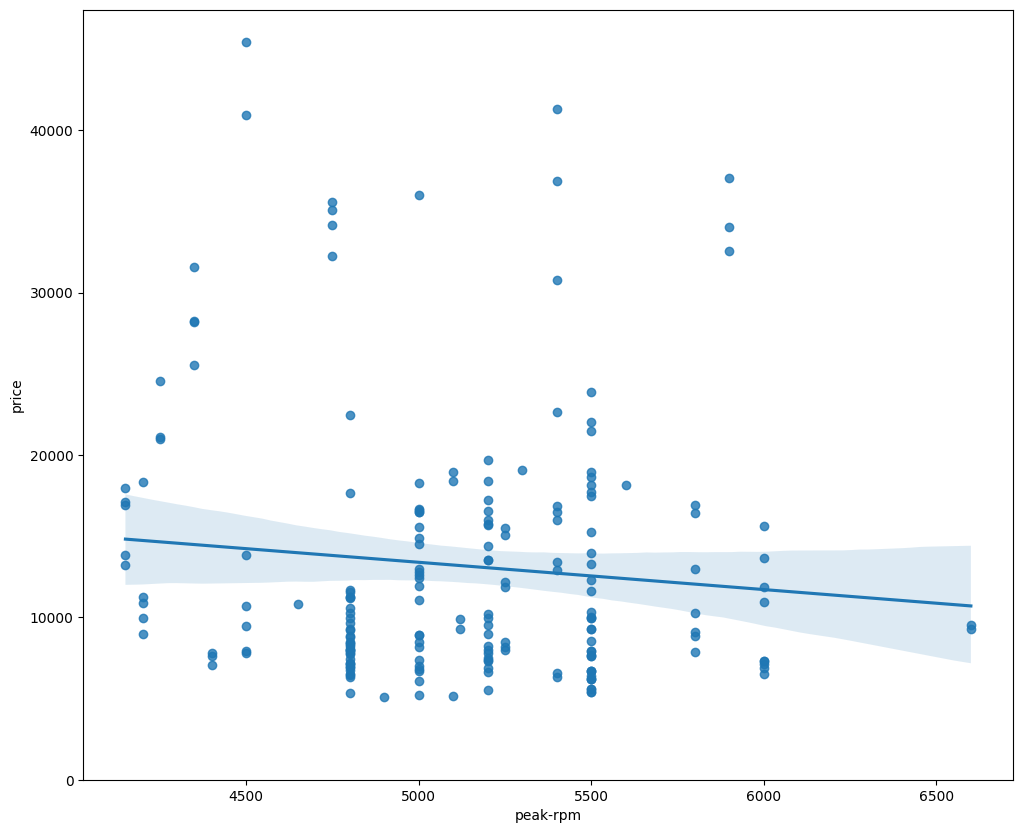

In [16]:
width = 12
height = 10
plt.figure(figsize=(width, height))
sns.regplot(x="peak-rpm", y="price", data=df)
plt.ylim(0,)

In [17]:
df[["peak-rpm","highway-mpg","price"]].corr()

,peak-rpm,highway-mpg,price
peak-rpm,1.000000,-0.060266,-0.101063
highway-mpg,-0.060266,1.000000,-0.704825
price,-0.101063,-0.704825,1.000000


<Axes: xlabel='highway-mpg', ylabel='price'>

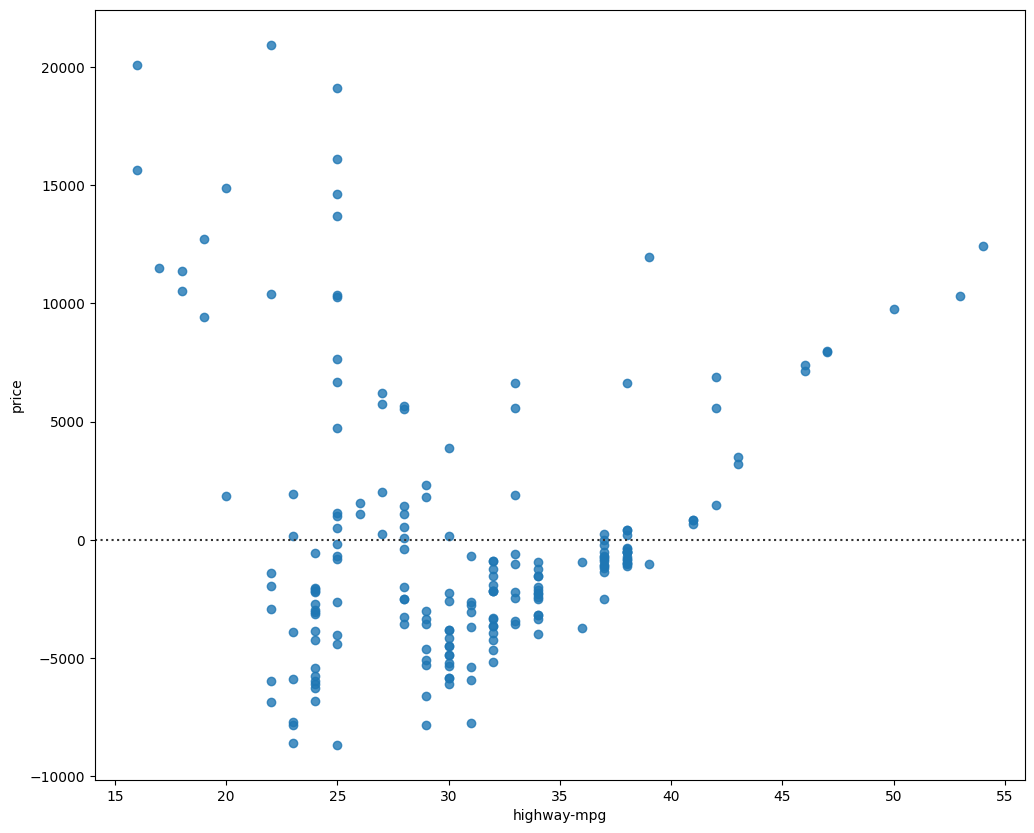

In [18]:
width = 12
height = 10
plt.figure(figsize=(width, height))
sns.residplot(x="highway-mpg", y="price", data=df)

In [19]:
Z.head()

,horsepower,curb-weight,engine-size,highway-mpg
0,111,2548,130,27
1,102,2337,109,30
2,115,2824,136,22
3,110,2507,136,25
4,110,2844,136,25


In [20]:
lm_multi = LinearRegression()
lm_multi.fit(Z, df["price"])
print(f"lm_multi coef = {lm_multi.coef_}\nlm_multi intercept = {lm_multi.intercept_} ")
y_hat = lm_multi.predict(Z)
y_hat[0:10]

lm_multi coef = [54.86114775  4.71004557 80.95463228 38.43821177]
lm_multi intercept = -15939.06836276877 


array([13713.64906747, 10641.34647958, 15526.60297101, 13874.52742143,
       15461.81277896, 15979.91779181, 17650.51401958, 10740.27513092,
       10740.27513092, 17816.18363681])

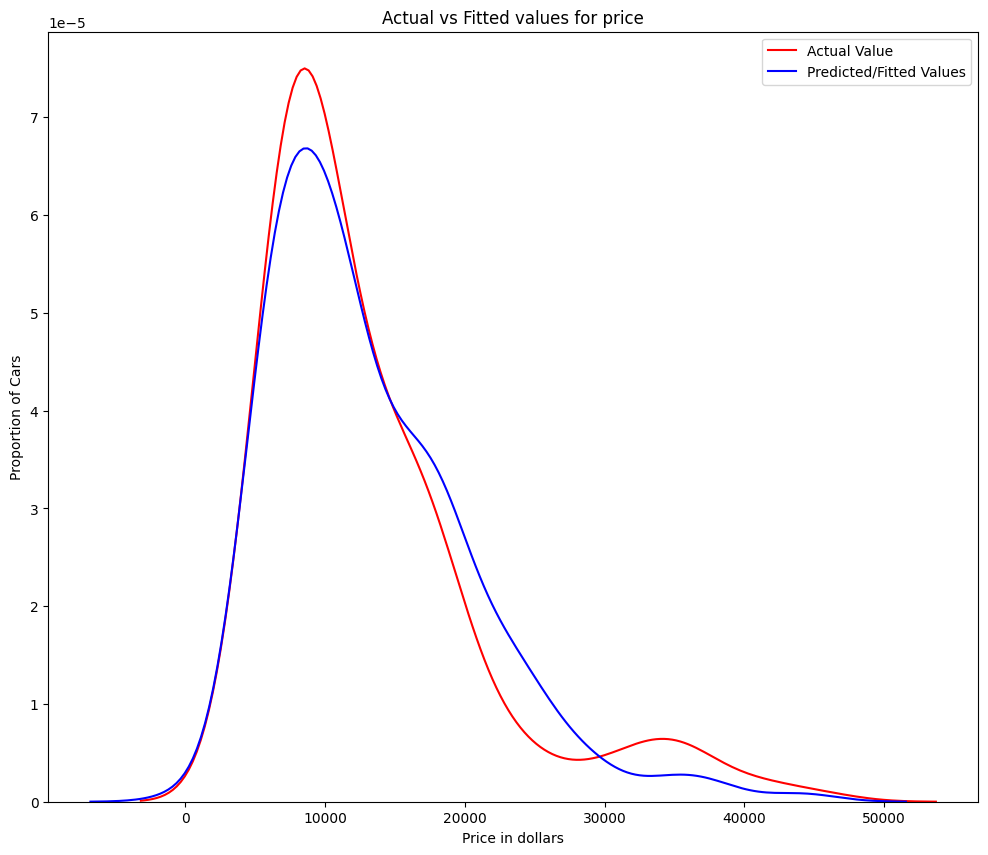

In [21]:
plt.figure(figsize=(width, height))
ax1 = sns.kdeplot(Y, color='r', label='Actual Value')
sns.kdeplot(y_hat, color='b', label='Predicted/Fitted Values', ax=ax1)

plt.title('Actual vs Fitted values for price')
plt.xlabel('Price in dollars')
plt.ylabel('Proportion of Cars')
plt.legend()
plt.show()

In [22]:
x = df['highway-mpg']
y = df['price']

f = np.polyfit(x,y,3)
p = np.poly1d(f)
print(p)

        3         2
-1.555 x + 204.5 x - 8958 x + 1.378e+05


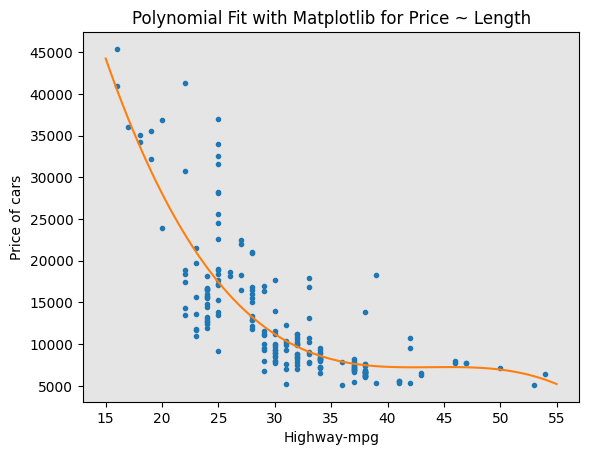

In [23]:
model = p
x_new = np.linspace(15, 55, 100)
y_new = model(x_new)

plt.plot(x,y,'.', x_new, y_new,'-' )
plt.xlabel("Highway-mpg")
plt.ylabel('Price of cars')
plt.title('Polynomial Fit with Matplotlib for Price ~ Length')

ax = plt.gca()
ax.set_facecolor((0.898, 0.898, 0.898))

In [24]:
def PlotPolly(model, independet_varaible, target_variable, name, order):
    x_new = np.linspace(15,55,100)
    y_new = model(x_new)

    plt.plot(independet_varaible, target_variable, '.', x_new, y_new, "-")
    ax = plt.gca()
    ax.set_facecolor((0.898, 0.898, 0.898))
    plt.ylabel('Price of Cars')
    plt.xlabel(name)
    plt.title(f'Polynomial fit for {name} againts price in {order} order')
    

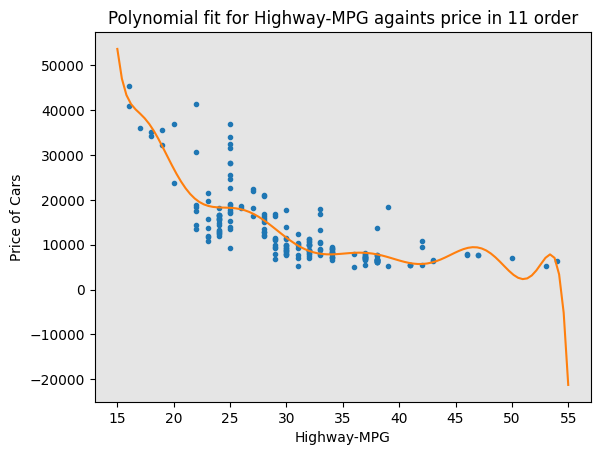

In [25]:
f1 = np.polyfit(x,y,11)
p2 = np.poly1d(f1)


PlotPolly(p2, x, y, "Highway-MPG", 11)

In [26]:
p2

poly1d([-1.28133542e-08,  4.86945826e-06, -8.28040640e-04,  8.31031491e-02,
       -5.46510917e+00,  2.47086850e+02, -7.83101695e+03,  1.73860155e+05,
       -2.64821540e+06,  2.63436819e+07, -1.53987572e+08,  4.00716664e+08])

In [27]:
#polynormial fit on multiple features
from sklearn.preprocessing import PolynomialFeatures

pr = PolynomialFeatures(degree=2)
pr

,degree,2
,interaction_only,False
,include_bias,True
,order,'C'


In [28]:
Z_pr = pr.fit_transform(Z)
Z_pr

array([[1.0000e+00, 1.1100e+02, 2.5480e+03, ..., 1.6900e+04, 3.5100e+03,
        7.2900e+02],
       [1.0000e+00, 1.0200e+02, 2.3370e+03, ..., 1.1881e+04, 3.2700e+03,
        9.0000e+02],
       [1.0000e+00, 1.1500e+02, 2.8240e+03, ..., 1.8496e+04, 2.9920e+03,
        4.8400e+02],
       ...,
       [1.0000e+00, 1.3400e+02, 3.0120e+03, ..., 2.9929e+04, 3.9790e+03,
        5.2900e+02],
       [1.0000e+00, 1.0600e+02, 3.2170e+03, ..., 2.1025e+04, 3.9150e+03,
        7.2900e+02],
       [1.0000e+00, 1.1400e+02, 3.0620e+03, ..., 1.9881e+04, 3.5250e+03,
        6.2500e+02]])

In [29]:
Z.shape

(199, 4)

In [30]:
Z_pr.shape

(199, 15)

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

In [32]:
#creating a pipeline
input = [
    ('scale', StandardScaler()),
    ('polynomial', PolynomialFeatures(include_bias=False, degree=11)),
    ('model', LinearRegression())
    ]

pipe=Pipeline(input)
pipe

,steps,"[('scale', ...), ('polynomial', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,11
,interaction_only,False
,include_bias,False
,order,'C'


In [33]:
Z = Z.astype('float')
pipe.fit(Z,y)

,steps,"[('scale', ...), ('polynomial', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,11
,interaction_only,False
,include_bias,False
,order,'C'


In [34]:
ypipe = pipe.predict(Z)

In [35]:
ypipe[0:10]

array([16501.04081662, 13949.70632453, 17449.87362706, 15248.03314092,
       17710.68882304, 18921.13458675, 23875.0084467 , 16677.55738849,
       16677.55738849, 20970.46124399])

In [36]:
Z

,horsepower,curb-weight,engine-size,highway-mpg
0,111.0,2548.0,130.0,27.0
1,102.0,2337.0,109.0,30.0
2,115.0,2824.0,136.0,22.0
3,110.0,2507.0,136.0,25.0
4,110.0,2844.0,136.0,25.0
...,...,...,...,...
194,114.0,2952.0,141.0,28.0
195,160.0,3049.0,141.0,25.0
196,134.0,3012.0,173.0,23.0
197,106.0,3217.0,145.0,27.0


In [37]:
input = [
    ('scale', StandardScaler()),
    ('model', LinearRegression())
]

pipe2 = Pipeline(input)
pipe2.fit(Z,y)

,steps,"[('scale', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None


In [38]:
ypipe2 = pipe2.predict(Z)
ypipe[0:10]

array([16501.04081662, 13949.70632453, 17449.87362706, 15248.03314092,
       17710.68882304, 18921.13458675, 23875.0084467 , 16677.55738849,
       16677.55738849, 20970.46124399])

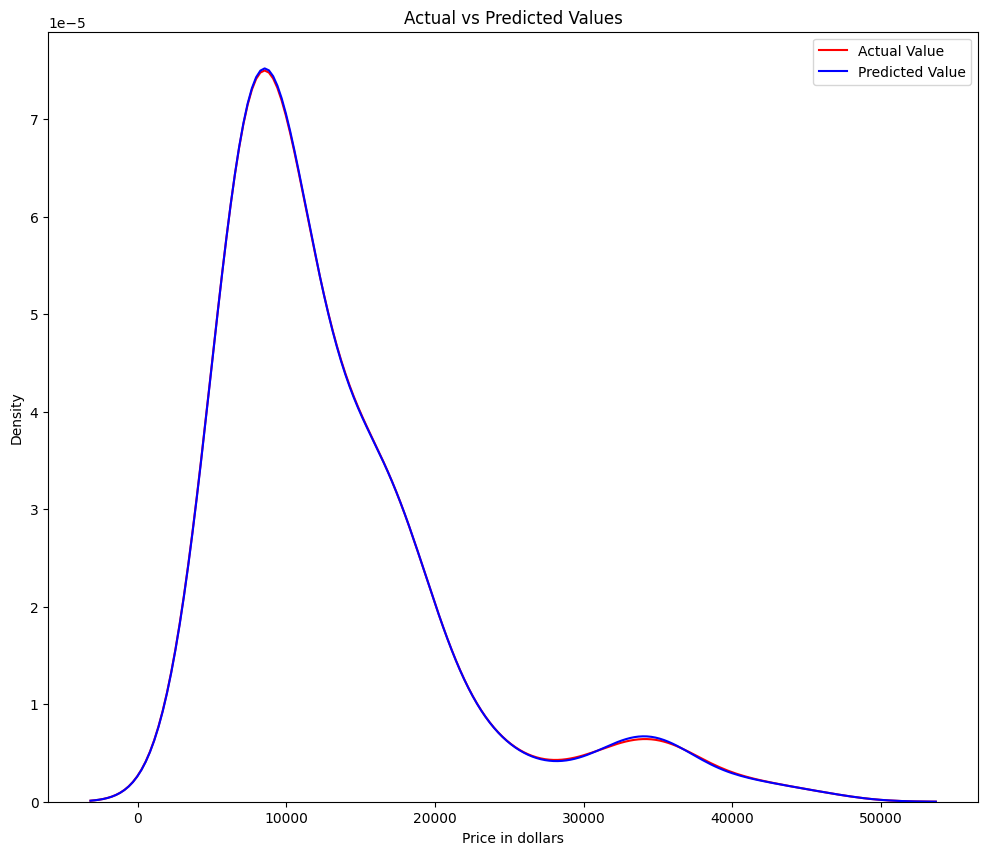

In [39]:
plt.figure(figsize=(width, height))
ax1 = sns.kdeplot(y, color='r', label="Actual Value")
sns.kdeplot(ypipe, color='b', label="Predicted Value", ax=ax1)

plt.title('Actual vs Predicted Values')
plt.xlabel('Price in dollars')
plt.ylabel('Density')
plt.legend()
plt.show()
plt.close()

In [40]:
#insample evaluation
x1 = df[["highway-mpg"]]
y1 = df["price"]

lm2 = LinearRegression()
lm2.fit(x1,y1)
lm2.score(x1,y1)

0.4967787813959448

In [41]:
#mean square error
yhat2 = lm2.predict(x1)
mean_absolute_error(df["price"], yhat2)

4085.007344899293

In [42]:
yhat2[0:5]

array([16258.2689376 , 13788.89891638, 20373.88563964, 17904.51561842,
       17904.51561842])

In [43]:
#MLR evaluation
lm.fit(Z, df["price"])
lm.score(Z, df["price"])

0.8098055008719582

In [44]:
#MSE of MLR
y_pred = lm.predict(Z)
mean_absolute_error(df["price"], y_pred)

2463.275281065604

In [ ]:
#polynomial fit evaluation
x=df['highway-mpg']
y=df["price"]

f = np.polyfit(x,y,3)
p = np.poly1d(f)

r_squared = r2_score(y, p(x))
r_squared

0.6740192474171374

In [46]:
#MSE of polynomial fit
mean_absolute_error(df["price"], p(x))

2974.0815949059447

In [47]:
new_input = np.arange(1,100,1).reshape(-1,1)

In [48]:
lm.fit(X,Y)
yhta= lm.predict(new_input)


/home/masila/.local/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [49]:
yhta[0:5]

array([-7799.35617165, -7632.42799619, -7465.49982073, -7298.57164527,
       -7131.64346981])

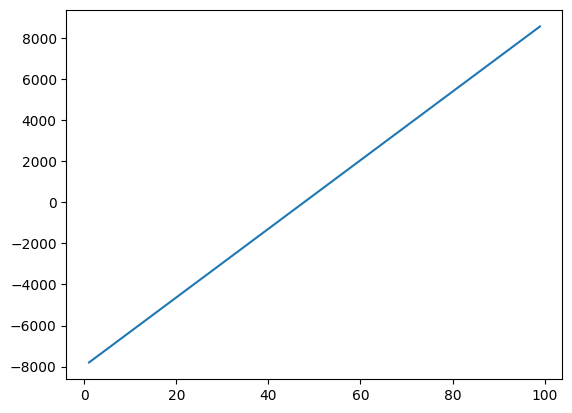

In [50]:
plt.plot(new_input, yhta)